In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
from sklearn.utils import class_weight

# 전처리된 데이터가 있는 경로
BASE_DIR = "data/processed"
TRAIN_PATH = os.path.join(BASE_DIR, "train.npz")
VAL_PATH = os.path.join(BASE_DIR, "val.npz")
TEST_PATH = os.path.join(BASE_DIR, "test.npz")

# 모델과 그래프를 저장할 폴더 생성
OUTPUT_DIR = "model_output"
if not os.path.exists(OUTPUT_DIR):
    os.makedirs(OUTPUT_DIR)

# 하이퍼파라미터
NUM_CLASSES = 4       # 클래스 개수
BATCH_SIZE = 32       # 배치 사이즈
EPOCHS = 50           # 에폭
LEARNING_RATE = 0.001 # 학습률

print(f"TensorFlow Version: {tf.__version__}")
print(f"설정 완료. 데이터 경로: {BASE_DIR}")
print(f"결과 저장 경로: {OUTPUT_DIR}")

TensorFlow Version: 2.11.0
설정 완료. 데이터 경로: data/processed
결과 저장 경로: model_output


In [2]:
def load_data():
    if not os.path.exists(TRAIN_PATH):
        raise FileNotFoundError(f"파일을 찾을 수 없습니다: {TRAIN_PATH}")

    # allow_pickle=True 옵션을 추가하여 최신 NumPy 버전 호환성 확보
    # 1. Train 데이터 로드
    data_tr = np.load(TRAIN_PATH, allow_pickle=True)
    X_train, y_train = data_tr['X'], data_tr['y']
    X_train = np.expand_dims(X_train, axis=-1)  # (N, 64, T) -> (N, 64, T, 1)
    y_train = to_categorical(y_train, NUM_CLASSES)

    # 2. Validation 데이터 로드
    data_val = np.load(VAL_PATH, allow_pickle=True)
    X_val, y_val = data_val['X'], data_val['y']
    X_val = np.expand_dims(X_val, axis=-1)
    y_val = to_categorical(y_val, NUM_CLASSES)

    # 3. Test 데이터 로드
    data_te = np.load(TEST_PATH, allow_pickle=True)
    X_test, y_test = data_te['X'], data_te['y']
    X_test = np.expand_dims(X_test, axis=-1)
    y_test = to_categorical(y_test, NUM_CLASSES)

    return (X_train, y_train), (X_val, y_val), (X_test, y_test)

# 실행 및 확인
(X_train, y_train), (X_val, y_val), (X_test, y_test) = load_data()
input_shape = X_train.shape[1:]

print(f"훈련 데이터 형태: {X_train.shape}")
print(f"검증 데이터 형태: {X_val.shape}")
print(f"테스트 데이터 형태: {X_test.shape}")
print(f"입력 모양: {input_shape}")

훈련 데이터 형태: (10455, 64, 1001, 1)
검증 데이터 형태: (2226, 64, 1001, 1)
테스트 데이터 형태: (1100, 64, 1001, 1)
입력 모양: (64, 1001, 1)


In [3]:
def build_model(input_shape):
    model = Sequential([
        # 최신 Keras 권장: 명시적인 Input Layer 사용
        Input(shape=input_shape),

        Conv2D(32, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 4)),
        Dropout(0.25),

        Conv2D(64, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 4)),
        Dropout(0.25),

        Conv2D(128, (3, 3), activation='relu', padding='same'),
        MaxPooling2D((2, 4)),
        Dropout(0.25),

        Flatten(),
        Dense(128, activation='relu'),
        Dropout(0.5),
        Dense(NUM_CLASSES, activation='softmax')
    ])

    # optimizer와 metrics 설정 최신화
    model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy']) # 'acc' 대신 'accuracy' 명시
    return model

model = build_model(input_shape)
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 64, 1001, 32)      320       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 32, 250, 32)      0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 32, 250, 32)       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 32, 250, 64)       18496     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 16, 62, 64)       0         
 2D)                                                             
                                                                 
 dropout_1 (Dropout)         (None, 16, 62, 64)        0

In [4]:
# 최신 Keras에서는 .h5 대신 .keras 포맷을 권장합니다.
model_path = os.path.join(OUTPUT_DIR, "best_audio_model.keras")

checkpoint = ModelCheckpoint(
    filepath=model_path,
    monitor='val_loss',
    verbose=1,
    save_best_only=True,
    mode='min'
)

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1
)

print("모델 학습을 시작합니다.")

# --- 클래스 가중치 계산 ---
# y_train은 one-hot encoding 상태이므로 정수로 변환
y_integers = np.argmax(y_train, axis=1)

# sklearn 버전에 따라 class_weight.compute_class_weight 사용법 준수
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_integers),
    y=y_integers
)
class_weights = dict(enumerate(weights))

print(f"계산된 클래스 가중치: {class_weights}")

history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_val, y_val),
    callbacks=[checkpoint, early_stop, reduce_lr],
    class_weight=class_weights,
    verbose=1
)
print("학습이 완료되었습니다.")

모델 학습을 시작합니다.
계산된 클래스 가중치: {0: 1.5285087719298245, 1: 0.8347971893963589, 2: 1.374211356466877, 3: 0.7041352370689655}
Epoch 1/50
327/327 [==============================] - ETA: 0s - loss: 0.6442 - accuracy: 0.7841
Epoch 1: val_loss improved from inf to 0.11390, saving model to model_output\best_audio_model.keras
327/327 [==============================] - 108s 327ms/step - loss: 0.6442 - accuracy: 0.7841 - val_loss: 0.1139 - val_accuracy: 0.9982 - lr: 0.0010
Epoch 2/50
327/327 [==============================] - ETA: 0s - loss: 0.2545 - accuracy: 0.9292
Epoch 2: val_loss improved from 0.11390 to 0.07728, saving model to model_output\best_audio_model.keras
327/327 [==============================] - 108s 331ms/step - loss: 0.2545 - accuracy: 0.9292 - val_loss: 0.0773 - val_accuracy: 0.9960 - lr: 0.0010
Epoch 3/50
327/327 [==============================] - ETA: 0s - loss: 0.1779 - accuracy: 0.9472
Epoch 3: val_loss improved from 0.07728 to 0.04776, saving model to model_output\best_audio_m

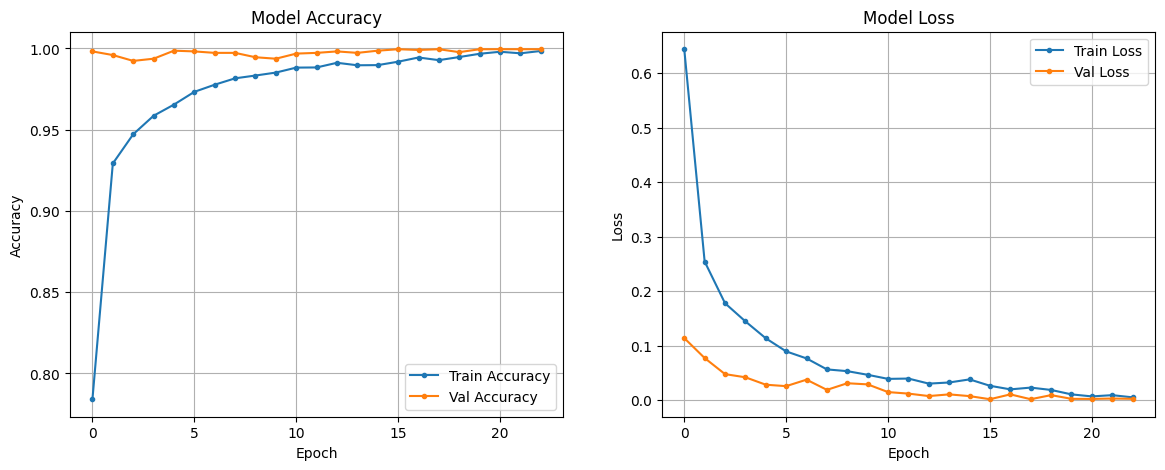

그래프 저장 완료: model_output


In [5]:
# history 키 확인 (버전 호환성)
acc_key = 'accuracy' if 'accuracy' in history.history else 'acc'
val_acc_key = 'val_accuracy' if 'val_accuracy' in history.history else 'val_acc'

plt.figure(figsize=(14, 5))

# 1. 정확도 그래프
plt.subplot(1, 2, 1)
plt.plot(history.history[acc_key], label='Train Accuracy', marker='.')
plt.plot(history.history[val_acc_key], label='Val Accuracy', marker='.')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# 2. 손실 그래프
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='.')
plt.plot(history.history['val_loss'], label='Val Loss', marker='.')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.savefig(os.path.join(OUTPUT_DIR, "training_history.png"))
plt.show()
print(f"그래프 저장 완료: {OUTPUT_DIR}")

In [6]:
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\n[최종 테스트 결과]")
print(f"Loss: {loss:.4f}")
print(f"Accuracy: {accuracy:.4f}")


[최종 테스트 결과]
Loss: 0.9616
Accuracy: 0.9345


In [8]:
# ================================
# 🔍 최종 모델 검증 코드 (Notebook 마지막 셀)
# ================================

import os
import numpy as np
import json
from tensorflow import keras
from tensorflow.keras.utils import to_categorical

print("\n==============================")
print("📌 최종 모델 검증을 시작합니다")
print("==============================\n")

# --- 경로 설정 ---
BASE_DIR = os.getcwd()
OUT_DIR = os.path.join(BASE_DIR, "data", "processed")
MODEL_DIR = os.path.join(BASE_DIR, "model_output")

TEST_PATH  = os.path.join(OUT_DIR, "test.npz")
STATS_PATH = os.path.join(OUT_DIR, "norm_stats.json")

# 🔥 체크포인트로 저장된 모델 파일명 자동 선택 (.keras 또는 .h5)
keras_path = os.path.join(MODEL_DIR, "best_audio_model.keras")
h5_path    = os.path.join(MODEL_DIR, "best_audio_model.h5")

if os.path.exists(h5_path):
    MODEL_PATH = h5_path
elif os.path.exists(keras_path):
    MODEL_PATH = keras_path
else:
    raise FileNotFoundError("best_audio_model.{keras/h5} 파일을 찾을 수 없습니다.")

print(f"📄 MODEL_PATH = {MODEL_PATH}")

# ================================
# 1) 테스트 데이터 로드
# ================================
print("\n--- 1) 테스트 데이터 로드 ---")

with open(STATS_PATH, "r") as f:
    stats = json.load(f)
    CLASSES = stats["classes"]

data_te = np.load(TEST_PATH)
X_test, y_test = data_te["X"], data_te["y"]

X_test = np.expand_dims(X_test, axis=-1)
y_test_onehot = to_categorical(y_test, num_classes=len(CLASSES))

print(f"✔ X_test shape = {X_test.shape}")
print(f"✔ y_test shape = {y_test_onehot.shape}")


# ================================
# 2) 모델 로드
# ================================
print("\n--- 2) 모델 로드 ---")
try:
    model = keras.models.load_model(MODEL_PATH, compile=False)
    print("✔ 모델 로드 성공!")
except Exception as e:
    print("❌ 모델 로드 실패:", e)
    raise

model.compile(optimizer="adam",
              loss="categorical_crossentropy",
              metrics=["accuracy"])


# ================================
# 3) 최종 평가
# ================================
print("\n--- 3) 최종 테스트 데이터 평가 ---")
loss, acc = model.evaluate(X_test, y_test_onehot, verbose=0)
print(f"🎯 Loss      : {loss:.4f}")
print(f"🎯 Accuracy  : {acc*100:.2f}%")

# ================================
# 4) 샘플 예측 출력
# ================================
print("\n--- 4) 샘플 예측 결과 ---")

num_samples = 1000
idx = np.random.choice(len(X_test), num_samples, replace=False)

pred = model.predict(X_test[idx])
y_pred = np.argmax(pred, axis=1)
y_true = np.argmax(y_test_onehot[idx], axis=1)

for i in range(num_samples):
    t = CLASSES[y_true[i]]
    p = CLASSES[y_pred[i]]
    conf = pred[i][y_pred[i]] * 100

    result = "✅ 정답" if t == p else "❌ 오답"
    print(f"[{i+1}] 실제:{t} / 예측:{p} ({conf:.1f}%) → {result}")

print("\n==============================")
print("🔍 검증 코드 실행 완료!")
print("==============================")


📌 최종 모델 검증을 시작합니다

📄 MODEL_PATH = D:\대학\3학년_2학기\Machine_Learning_final_project\model_output\best_audio_model.keras

--- 1) 테스트 데이터 로드 ---
✔ X_test shape = (1100, 64, 1001, 1)
✔ y_test shape = (1100, 4)

--- 2) 모델 로드 ---
✔ 모델 로드 성공!

--- 3) 최종 테스트 데이터 평가 ---
🎯 Loss      : 0.9616
🎯 Accuracy  : 93.45%

--- 4) 샘플 예측 결과 ---
32/32 [==============================] - 2s 71ms/step
[1] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[2] 실제:Chatting / 예측:Writing (100.0%) → ❌ 오답
[3] 실제:Game / 예측:Game (99.9%) → ✅ 정답
[4] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[5] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[6] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[7] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[8] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[9] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[10] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[11] 실제:Game / 예측:Game (99.6%) → ✅ 정답
[12] 실제:Game / 예측:Game (99.8%) → ✅ 정답
[13] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[14] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[15] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[16] 실제:Game / 예측:Game (100.0%) → ✅ 정답
[17] 